In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error


Production  = pd.read_csv("/Users/jeanmiccheltia/Documents/Electricity Germany Data.csv", sep=";", header=0)

In [2]:
Production = Production.rename(columns={
              "Datum von": "Date from",
              "Datum bis": "Date to",
              "Biomasse [MWh] Berechnete Auflösungen": "Biomass [MWh]",
              "Wasserkraft [MWh] Berechnete Auflösungen": "Hydropower [MWh]",
              "Wind Offshore [MWh] Berechnete Auflösungen":	"Offshore Wind [MWh]",
              "Wind Onshore [MWh] Berechnete Auflösungen": "Onshore Wind [MWh]",
              "Photovoltaik [MWh] Berechnete Auflösungen":"Photovoltaics [MWh]",
              "Sonstige Erneuerbare [MWh] Berechnete Auflösungen":"Other renewables [MWh]",
              "Kernenergie [MWh] Berechnete Auflösungen":"Nuclear energy [MWh]",
              "Braunkohle [MWh] Berechnete Auflösungen":"Lignite [MWh]",
              "Steinkohle [MWh] Berechnete Auflösungen": "Hard coal [MWh]",
              "Erdgas [MWh] Berechnete Auflösungen": "Natural gas [MWh]",
              "Pumpspeicher [MWh] Berechnete Auflösungen":"Pumped-storage [MWh]",
              "Sonstige Konventionelle [MWh] Berechnete Auflösungen": "Other Conventional [MWh]",
              "Netzlast [MWh] Berechnete Auflösungen": "Grid load [MWh]"
})

In [3]:
Production.head(5)

,Date from,Biomass [MWh],Hydropower [MWh],Offshore Wind [MWh],Onshore Wind [MWh],Photovoltaics [MWh],Other renewables [MWh],Nuclear energy [MWh],Lignite [MWh],Hard coal [MWh],Natural gas [MWh],Pumped-storage [MWh],Other Conventional [MWh],Grid load [MWh],Germany [€/MWh] Calculated
0,01.01.15,"112.626,35","27.849,64","12.620,56","315.602,00","16.409,41","4.687,30","251.484,49","314.599,99","60.723,50","23.804,29","13.972,68","19.072,45","1.106.343,98",NaN
1,02.01.15,"111.126,88","27.427,37","10.439,22","589.347,97","7.693,38","5.414,41","218.435,47","257.343,24","83.618,06","29.920,00","22.181,42","24.602,20","1.299.202,20",NaN
2,03.01.15,"111.216,57","31.946,96","12.235,09","459.127,42","7.446,26","5.781,71","245.250,96","296.727,83","60.998,77","29.790,67","27.335,79","26.186,14","1.223.922,79",NaN
3,04.01.15,"111.375,07","43.055,06","11.642,65","393.097,88","19.328,61","5.668,18","251.626,44","287.900,18","47.225,78","21.472,46","18.206,90","25.367,11","1.186.497,33",NaN
4,05.01.15,"110.442,66","38.869,76","7.822,47","230.092,28","26.628,70","5.598,82","267.080,86","405.170,67","177.046,99","35.150,77","24.467,55","26.414,27","1.436.304,78",NaN


In [4]:
#### The format of the data not conventional, need to be adjusted

cols = Production.columns.drop("Date from")
Production["Date from"]=pd.to_datetime(Production["Date from"])
Production[cols] = (
    Production[cols]
    .replace({r"\.": "", ",": "."}, regex=True)
    .apply(pd.to_numeric, errors="coerce")
)

/var/folders/np/v9js13r17k9_qp03z_bwglkh0000gn/T/ipykernel_2754/3474135708.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  Production["Date from"]=pd.to_datetime(Production["Date from"])


In [5]:
Production.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Date from                    4199 non-null   datetime64[ns]
 1   Biomass [MWh]                4199 non-null   float64       
 2   Hydropower [MWh]             4199 non-null   float64       
 3   Offshore Wind [MWh]          4199 non-null   float64       
 4   Onshore Wind [MWh]           4199 non-null   float64       
 5   Photovoltaics [MWh]          4199 non-null   float64       
 6   Other renewables [MWh]       4198 non-null   float64       
 7   Nuclear energy [MWh]         3316 non-null   float64       
 8   Lignite [MWh]                4199 non-null   float64       
 9   Hard coal [MWh]              4199 non-null   float64       
 10  Natural gas [MWh]            4199 non-null   float64       
 11  Pumped-storage [MWh]         4195 non-null 

##### Data cleansing, NB : price were available from first of October 2018

In [6]:
#### lets fill in the missing values for for the Other renewables energy and the pump storage.
#### the use of nuclear energy stopped , the energy price was giving from 01/10/2018

Production["Other renewables [MWh]"] = Production["Other renewables [MWh]"].ffill()
Production["Pumped-storage [MWh]"] = Production["Pumped-storage [MWh]"].ffill()

### DATA ANALYSIS, EXPLRATORY ANALYSIS

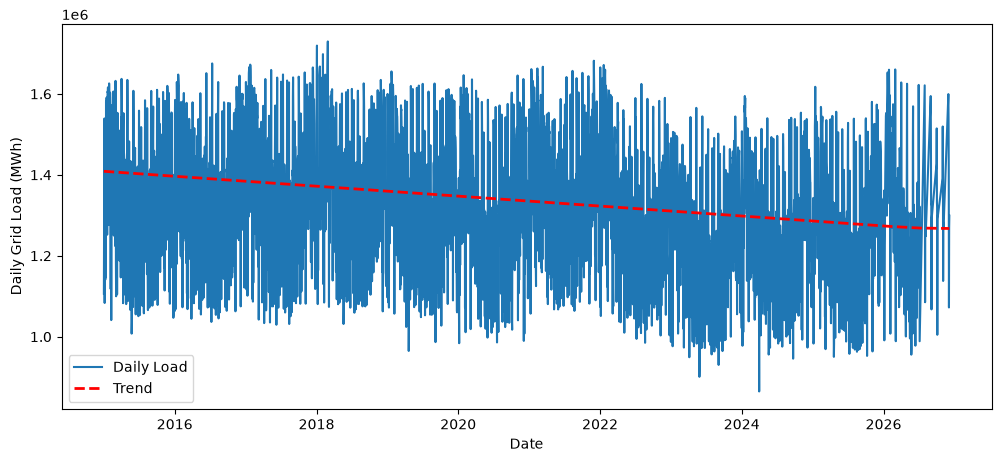

In [7]:
#### a downstream tendency observed from 2022.

daily_consumption = (
    Production.groupby(Production["Date from"].dt.date)["Grid load [MWh]"]
              .sum()
)

x = np.arange(len(daily_consumption))
y = daily_consumption.values

z = np.polyfit(x, y, 1)
trend = np.poly1d(z)

plt.figure(figsize=(12, 5))
plt.plot(daily_consumption.index, y, label="Daily Load")
plt.plot(daily_consumption.index, trend(x), 'r--', linewidth=2, label="Trend")

plt.xlabel("Date")
plt.ylabel("Daily Grid Load (MWh)")
plt.legend()
plt.show()

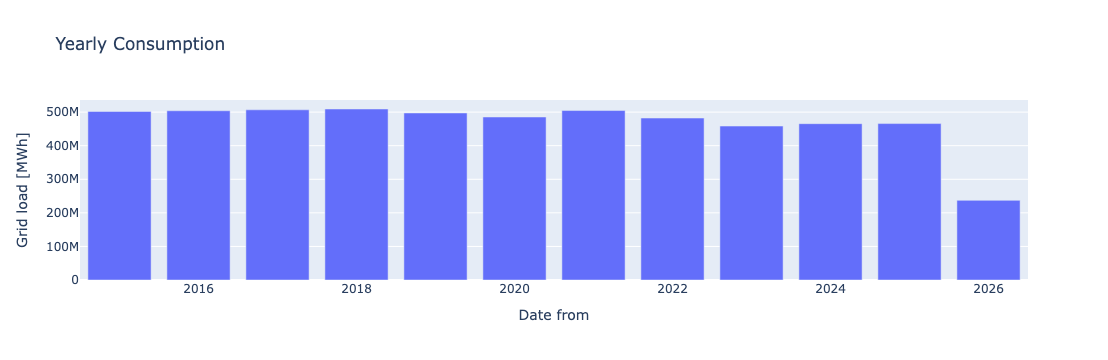

In [8]:
#### Prices are rising despite electricity consumption dropping. Rise occur during 2020-2021
#### the drop 

Consumption_year = (
    Production.groupby(Production["Date from"].dt.year)["Grid load [MWh]"]
              .sum()
)
fig = px.bar(
    Consumption_year,
    x=Consumption_year.index, 
    y=Consumption_year.values, 
    orientation="v", 
    title="Yearly Consumption",
    labels={'x': 'Year', 'y': 'Grid load [MWh]'}
)

fig.show()

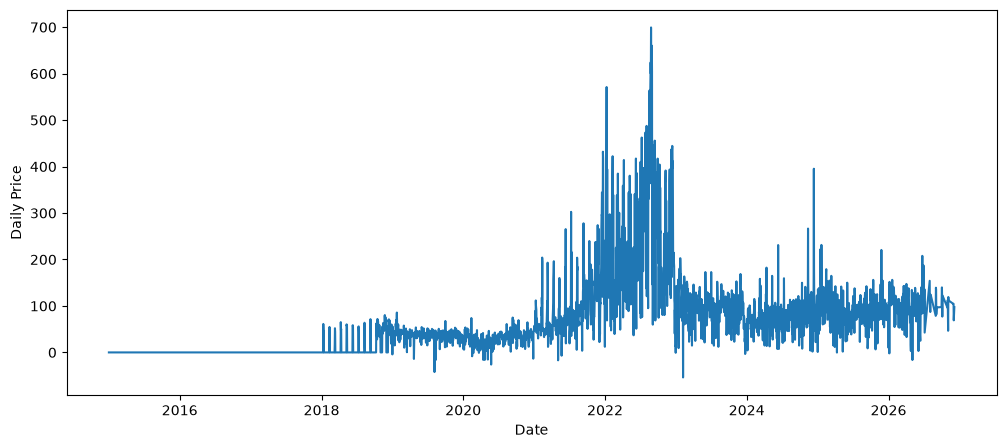

In [9]:
#### lets look at the daily electricity prive

daily_Price = (
    Production.groupby(Production["Date from"].dt.date)["Germany [€/MWh] Calculated "]
            .sum()
)

plt.figure(figsize=(12,5))
plt.plot(daily_consumption.index, daily_Price.values)
plt.xlabel("Date")
plt.ylabel("Daily Price")
plt.show()

##### Price grew with the Energy crisis during 2022-2023 with Ukraine war despite consumption down, Price did not reach previous levels of 2018-2021

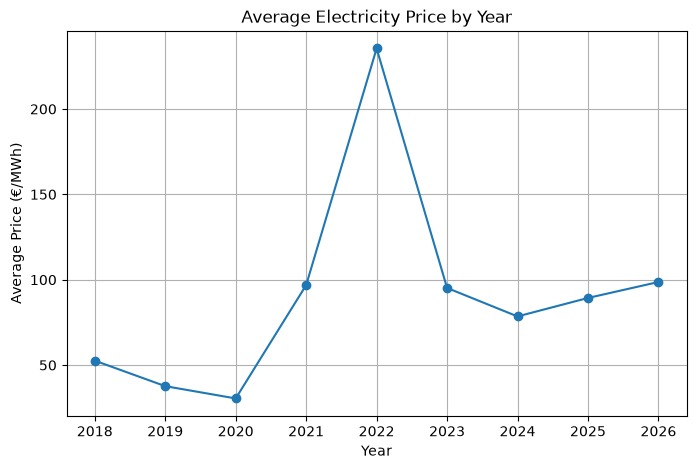

In [10]:
 
#### The previous levels prior of the crisis from a 50 €/MWh on average to close to 100 €/MWh on average

average_price_year = (
    Production.groupby(Production["Date from"].dt.year)["Germany [€/MWh] Calculated "]
              .mean()
)

plt.figure(figsize=(8,5))
plt.plot(average_price_year.index, average_price_year.values, marker='o')
plt.xlabel("Year")
plt.ylabel("Average Price (€/MWh)")
plt.title("Average Electricity Price by Year")
plt.grid(True)
plt.show()

##### at the start of the energy crisis of 2022, price reached an average of 240€/MWH almost 5 times what prices were in 2018

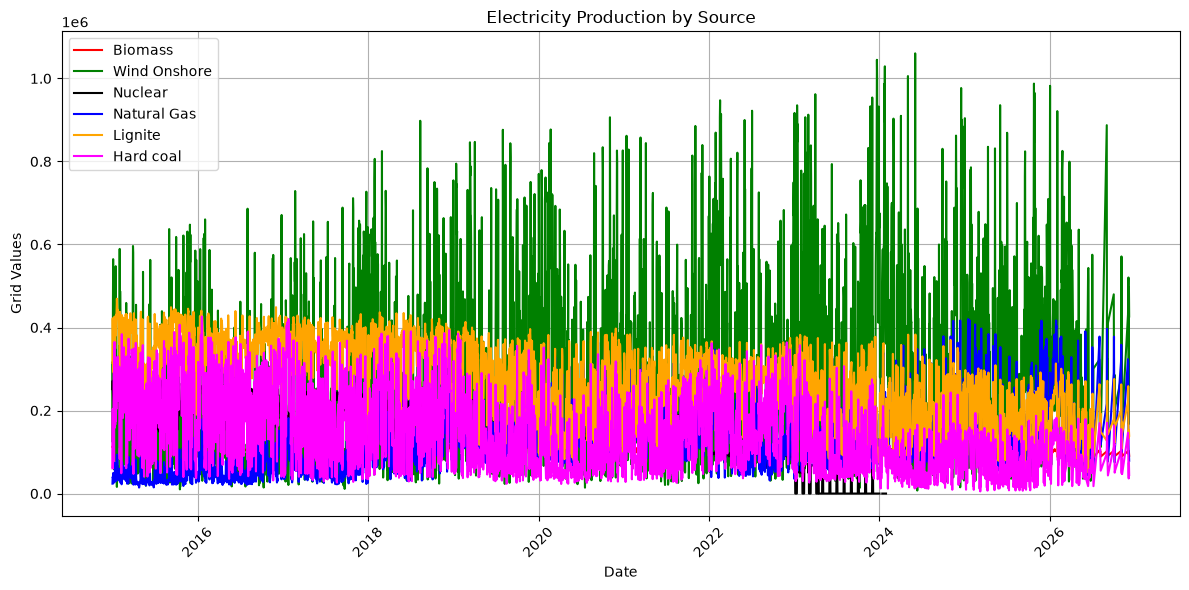

In [11]:
##### Lets find out the major components of the produced electricity

plt.figure(figsize=(12, 6))


Production = Production.sort_values("Date from")

plt.plot(Production["Date from"], Production["Biomass [MWh]"], color="red", label="Biomass")
plt.plot(Production["Date from"], Production["Onshore Wind [MWh]"], color="green", label="Wind Onshore")
plt.plot(Production["Date from"], Production["Nuclear energy [MWh]"], color="black", label="Nuclear")
plt.plot(Production["Date from"], Production["Natural gas [MWh]"], color="blue", label="Natural Gas")
plt.plot(Production["Date from"], Production["Lignite [MWh]"], color="orange", label="Lignite")
plt.plot(Production["Date from"], Production["Hard coal [MWh]"], color="magenta", label="Hard coal")


plt.xlabel("Date")
plt.ylabel("Grid Values")
plt.title("Electricity Production by Source")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

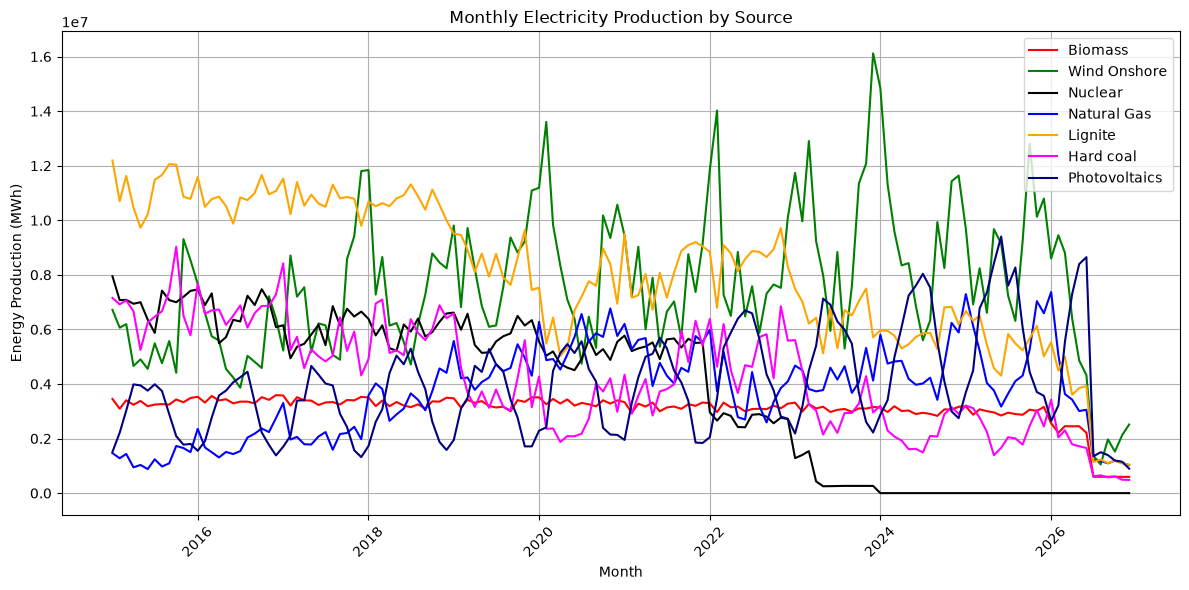

In [12]:
monthly = (
    Production
    .set_index("Date from")
    .resample("MS")   
    .sum()           
)

plt.figure(figsize=(12,6))

plt.plot(monthly.index, monthly["Biomass [MWh]"], color="red", label="Biomass")
plt.plot(monthly.index, monthly["Onshore Wind [MWh]"], color="green", label="Wind Onshore")
plt.plot(monthly.index, monthly["Nuclear energy [MWh]"], color="black", label="Nuclear")
plt.plot(monthly.index, monthly["Natural gas [MWh]"], color="blue", label="Natural Gas")
plt.plot(monthly.index, monthly["Lignite [MWh]"], color="orange", label="Lignite")
plt.plot(monthly.index, monthly["Hard coal [MWh]"], color="magenta", label="Hard coal")
plt.plot(monthly.index, monthly["Photovoltaics [MWh]"], color="navy", label="Photovoltaics")

plt.xlabel("Month")
plt.ylabel("Energy Production (MWh)")
plt.title("Monthly Electricity Production by Source")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

##### Nuclear production stopped in 2023,electricity produced from Lignite , Hard coal , Biomass
##### are going down, while renewable energy are on the rise, Wind Onshore a, photovoltaics
##### the use of Natural Gas is an important part of electricty, with a drop in 2021-2023, but a rebound in 2024

### MODEL SELECTION

#### Lets start with the traditional Statistical method Sarima models

In [13]:
### lets take a look at the consumption

df = Production[["Date from","Grid load [MWh]"]]
df = df.set_index("Date from")

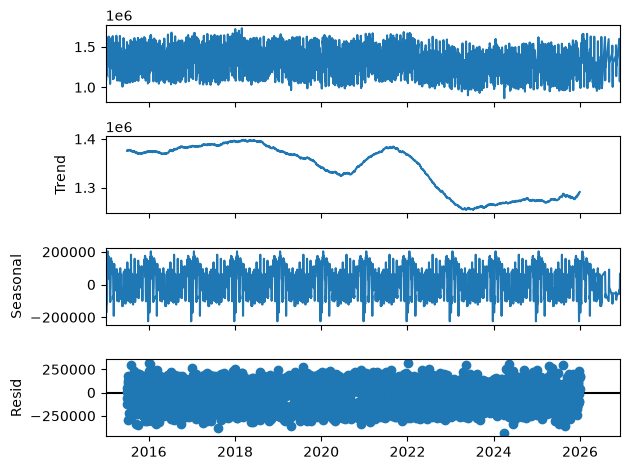

In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    df,
    model="additive",
    period=365
)

decomposition.plot()
plt.show()

Available seasonal components:
Index(['seasonal_7', 'seasonal_30', 'seasonal_365'], dtype='object')

Result object attributes:
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_observed', '_resid', '_seasonal', '_trend', '_weights', 'nobs', 'observed', 'plot', 'resid', 'seasonal', 'trend', 'weights']


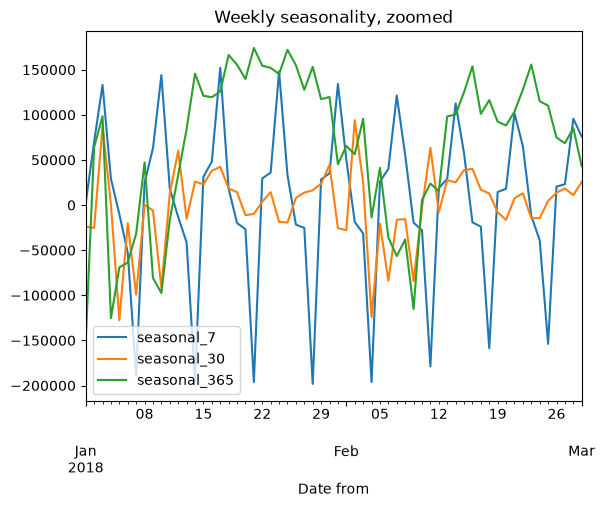

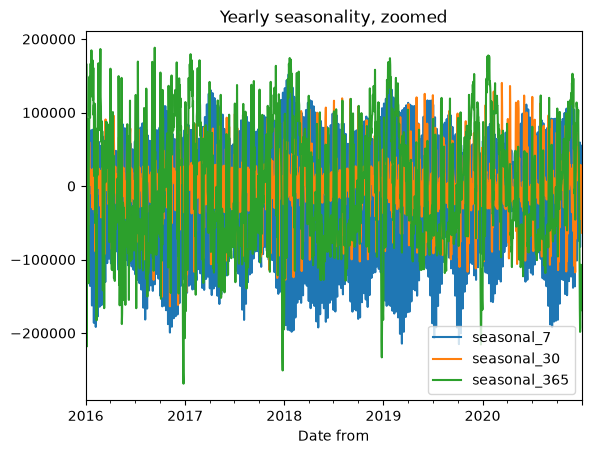

In [15]:
### the residuals spread over 0 , the trend shows a drop from 2022 and a slight recover in subsequent year 
#### however level of post energy crisis have not been reached setting a new path
#### lets look at the trend a little more closer

from statsmodels.tsa.seasonal import MSTL

periods = [7, 30, 365]
mstl = MSTL(df, periods=periods, iterate=3)
result = mstl.fit()

print("Available seasonal components:")
print(result.seasonal.keys())


print("\nResult object attributes:")
print(dir(result))


result.seasonal.loc['2018-01-01':'2018-03-01'].plot(title='Weekly seasonality, zoomed')
plt.show()


result.seasonal.loc['2016':'2020'].plot(title='Yearly seasonality, zoomed')
plt.show()

In [16]:
### lets find the important lag features

from scipy.signal import periodogram
import numpy as np

series = df['Grid load [MWh]'].dropna()
freqs, power = periodogram(series)
periods = 1 / freqs[1:]
power = power[1:]

top_idx = np.argsort(power)[-10:][::-1]
for i in top_idx:
    print(f"period ≈ {periods[i]:.1f} days, power = {power[i]:.2e}")

period ≈ 7.0 days, power = 1.25e+13
period ≈ 4199.0 days, power = 7.06e+12
period ≈ 10.1 days, power = 3.04e+12
period ≈ 5.7 days, power = 3.01e+12
period ≈ 9.1 days, power = 3.00e+12
period ≈ 349.9 days, power = 2.87e+12
period ≈ 3.5 days, power = 2.83e+12
period ≈ 15.2 days, power = 2.51e+12
period ≈ 381.7 days, power = 2.20e+12
period ≈ 3.0 days, power = 1.55e+12


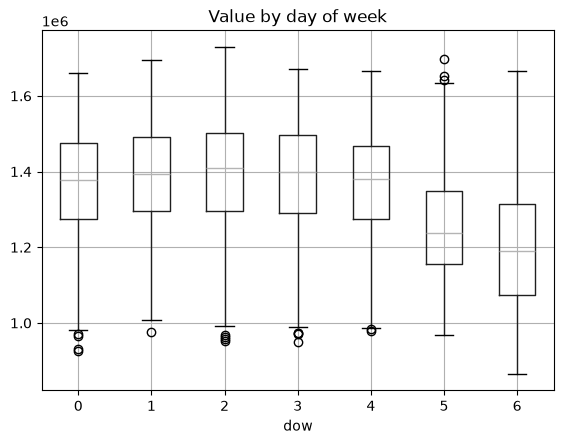

In [17]:
### Notice period ≈ 7.0 has by far the highest power (1.25e+13) — nearly double the next contender. 
### Ntice period = 10.1 and 5.7 shows the importance of the Mondays and a different behaviour during weekends 

df['dow'] = df.index.dayofweek  # 0=Monday ... 6=Sunday
df.boxplot(column='Grid load [MWh]', by='dow')
plt.title('Value by day of week')
plt.suptitle('')
plt.show()

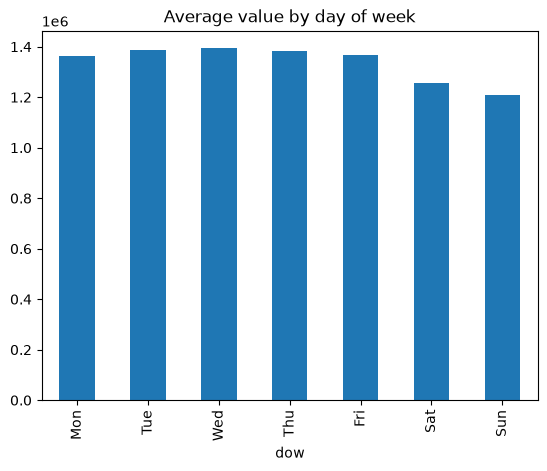

In [18]:
df['dow'] = df.index.dayofweek
df.groupby('dow')['Grid load [MWh]'].mean().plot(kind='bar')
plt.xticks(range(7), ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
plt.title('Average value by day of week')
plt.show()

In [19]:
df = df.drop(columns="dow")
train = df[df.index < "2024-01-01"]
test = df[(df.index >= "2024-01-01") & (df.index <= "2026-06-30")]
train.head(2)

,Grid load [MWh]
Date from,
2015-01-01,1106343.98
2015-01-02,1260981.02


ADF test (original): statistic=-5.313, p-value=0.0000
  -> stationary
ADF test (first difference): statistic=-24.655, p-value=0.0000
  -> stationary


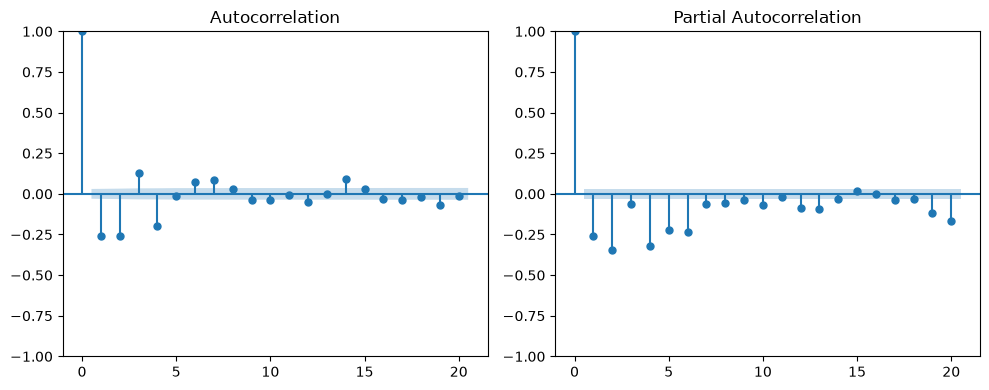

In [20]:
#### lets check the stationarity of the time series to find out if there wll be a need to differenciate or
#### and find out the lag needed 

def check_stationarity(ts, label=""):
    result = adfuller(ts.dropna())
    print(f"ADF test ({label}): statistic={result[0]:.3f}, p-value={result[1]:.4f}")
    print("  -> stationary" if result[1] < 0.05 else "  -> non-stationary")

check_stationarity(df, "original")
check_stationarity(df.diff(), "first difference")

# ACF / PACF (saved to file rather than shown interactively)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(df.diff().dropna(), ax=axes[0], lags=20)
plot_pacf(df.diff().dropna(), ax=axes[1], lags=20)
plt.tight_layout()
plt.savefig("acf_pacf.png", dpi=100)
plt.show()

##### the series is stationary so no need to differenciate, 
##### we note the cut off at lag 3 of the ACF,the PACF shows a change from Lag 2

In [21]:
### lets implement the first model the baseline model in Sarima

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error



model1 = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7)
)
model_fit1 = model1.fit()
print(model_fit1.summary())
forecast1 = model_fit1.forecast(steps=len(test))
mae = mean_absolute_error(test, forecast1)
rmse = np.sqrt(mean_squared_error(test, forecast1))
mape = mean_absolute_percentage_error(test, forecast1)
print("SARIMA MAPE:", mape)
print("SARIMA MAE:", mae)
print("SARIMA RMSE:", rmse)

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            5     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.33917D+01    |proj g|=  1.59799D-01

At iterate    5    f=  1.32864D+01    |proj g|=  3.15205D-03

At iterate   10    f=  1.32844D+01    |proj g|=  9.84738D-04

At iterate   15    f=  1.32813D+01    |proj g|=  5.73222D-04

At iterate   20    f=  1.32751D+01    |proj g|=  1.38282D-02

At iterate   25    f=  1.32727D+01    |proj g|=  9.51198D-04

At iterate   30    f=  1.32721D+01    |proj g|=  3.15561D-03

At iterate   35    f=  1.32712D+01    |proj g|=  4.78623D-04

At iterate   40    f=  1.32712D+01    |proj g|=  1.15542D-04

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg 

##### We obtained a MAPE of 9.6% and a RMSE of 148831 MWH/day 

In [22]:
### lets improve with the model of our choice based on the analysis of the ACF & PACF

model2 = SARIMAX(
    train,
    order=(3, 0, 2),
    seasonal_order=(1, 0, 1, 7)
)
model_fit2 = model2.fit()
print(model_fit2.summary())
forecast2 = model_fit2.forecast(steps=len(test))
mae = mean_absolute_error(test, forecast2)
rmse = np.sqrt(mean_squared_error(test, forecast2))
mape = mean_absolute_percentage_error(test, forecast2)
print("MAPE:", mape)
print("MAE:", mae)
print("RMSE:", rmse)

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/opt/anaconda3/envs/tf/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            8     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.33404D+01    |proj g|=  3.34387D-01

At iterate    5    f=  1.32441D+01    |proj g|=  4.06970D-02

At iterate   10    f=  1.32353D+01    |proj g|=  3.77331D-03

At iterate   15    f=  1.32348D+01    |proj g|=  4.86472D-03

At iterate   20    f=  1.32304D+01    |proj g|=  1.51895D-02

At iterate   25    f=  1.32201D+01    |proj g|=  8.74689D-03

At iterate   30    f=  1.32133D+01    |proj g|=  9.62790D-03

At iterate   35    f=  1.32112D+01    |proj g|=  1.88219D-03

At iterate   40    f=  1.32106D+01    |proj g|=  7.56783D-04

At iterate   45    f=  1.32106D+01    |proj g|=  1.64983D-04

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = nu

##### The MAPE is at 9.4% but the RMSE increased by 3341 MWH meaning that some large predicions (holidays, sundays...) became worse

#### Lets select a model that is a transitional model between traditional statistical models and Machine Learning Model "Prophet"

In [23]:


from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error 


prophet_train = train.reset_index()
prophet_train.columns = ['ds', 'y'] + list(prophet_train.columns[2:])
prophet_train = prophet_train[['ds', 'y']]  

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)
model.fit(prophet_train)

last_train_date = train.index.max()
last_test_date = test.index.max()
periods_needed = (last_test_date - last_train_date).days

future = model.make_future_dataframe(periods=periods_needed, freq='D')
forecast_p = model.predict(future)

forecast_indexed = forecast_p.set_index('ds')
available_test_dates = forecast_indexed.index.intersection(test.index)
forecast_test_p = forecast_indexed.loc[available_test_dates, 'yhat'] 

y_true = test["Grid load [MWh]"]


prophet_mape_value = mean_absolute_percentage_error(y_true, forecast_test_p) 
prophet_mae_value = mean_absolute_error(y_true, forecast_test_p)
prophet_rmse_value = np.sqrt(mean_squared_error(y_true, forecast_test_p))

print(f"Prophet MAPE : {prophet_mape_value*100:,.2f} %")
print(f"Prophet MAE  : {prophet_mae_value:,.2f} MWh")
print(f"Prophet RMSE : {prophet_rmse_value:,.2f} MWh")

14:46:57 - cmdstanpy - INFO - Chain [1] start processing
14:46:58 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAPE : 11.47 %
Prophet MAE  : 152,296.27 MWh
Prophet RMSE : 185,749.98 MWh


In [24]:
model_p1 = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode='multiplicative'
)
model_p1.fit(prophet_train)

last_train_date = train.index.max()
last_test_date = test.index.max()
periods_needed = (last_test_date - last_train_date).days

future = model_p1.make_future_dataframe(periods=periods_needed, freq='D')
forecast_p1 = model_p1.predict(future)

forecast_indexed = forecast_p1.set_index('ds')
available_test_dates = forecast_indexed.index.intersection(test.index)
forecast_test_p1 = forecast_indexed.loc[available_test_dates, 'yhat'] 

y_true = test["Grid load [MWh]"]


prophet_mape_value = mean_absolute_percentage_error(y_true, forecast_test_p1) 
prophet_mae_value = mean_absolute_error(y_true, forecast_test_p1)
prophet_rmse_value = np.sqrt(mean_squared_error(y_true, forecast_test_p1))

print(f"Prophet MAPE : {prophet_mape_value*100:,.2f} %")
print(f"Prophet MAE  : {prophet_mae_value:,.2f} MWh")
print(f"Prophet RMSE : {prophet_rmse_value:,.2f} MWh")

14:47:03 - cmdstanpy - INFO - Chain [1] start processing
14:47:03 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAPE : 11.57 %
Prophet MAE  : 154,373.62 MWh
Prophet RMSE : 188,251.64 MWh


##### The ML model does not improve nor the MAPE or the RMSE, leaving the statistical model as the best
##### lets try a deep learning model LSTM
####   Lets compare with a Deep Learning Model "LSTM"

In [25]:
from sklearn.preprocessing import MinMaxScaler

target = "Grid load [MWh]"
train_values = train[target].values
test_values = test[target].values

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_values.reshape(-1,1))
test_scaled = scaler.transform(test_values.reshape(-1,1))

lookback = 7


In [26]:
def create_sequences(data, lookback):
    X, y = [], []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i])
        y.append(data[i])

    return np.array(X), np.array(y)
X_train, y_train = create_sequences(train_scaled, lookback)
combined = np.concatenate((train_scaled[-lookback:], test_scaled))
X_test, y_test = create_sequences(combined, lookback)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)

(3280, 7, 1)
(3280, 1)
(876, 7, 1)


In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential()
model.add(LSTM(64,
               return_sequences=True,
               input_shape=(X_train.shape[1],
                            X_train.shape[2])))
model.add(Dropout(0.2))
model.add(LSTM(32))
model.add(Dropout(0.2))
model.add(Dense(1))
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False
)
pred = model.predict(X_test)
pred = scaler.inverse_transform(pred)
y_test = scaler.inverse_transform(y_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mape = mean_absolute_percentage_error(y_test, pred)

print(f"LSTM MAPE :    {mape*100:,.2f} %")
print(f"LSTM MAE  : {mae:,.2f} MWh")
print(f"LSTM RMSE : {rmse:,.2f} MWh")

Epoch 1/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0661 - mae: 0.2010 - val_loss: 0.0347 - val_mae: 0.1429
Epoch 2/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0402 - mae: 0.1629 - val_loss: 0.0368 - val_mae: 0.1460
Epoch 3/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0401 - mae: 0.1634 - val_loss: 0.0354 - val_mae: 0.1439
Epoch 4/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0393 - mae: 0.1619 - val_loss: 0.0378 - val_mae: 0.1481
Epoch 5/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0388 - mae: 0.1602 - val_loss: 0.0408 - val_mae: 0.1543
Epoch 6/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0384 - mae: 0.1597 - val_loss: 0.0386 - val_mae: 0.1501
Epoch 7/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0390 - mae: 0.1606 - val_loss: 0.0390 - val_mae: 0.1508
Epoch 8/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0383 - mae: 0.1591 - val_loss: 0.0385 - val_mae: 0.1499
Epoch 9/30
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0385 - mae: 

##### due to the encouraging start lets look at a more complex LSTM by choosing among several lookback, month and quarter

In [36]:
lookback = 30
model = Sequential()
model.add(LSTM(64,
               return_sequences=True,
               input_shape=(X_train.shape[1],
                            X_train.shape[2])))
model.add(Dropout(0.2))
model.add(LSTM(32))
model.add(Dropout(0.2))
model.add(Dense(1))
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_5 (LSTM)                   │ (None, 92, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 92, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False
)
pred = model.predict(X_test)
pred = scaler.inverse_transform(pred)
y_test = scaler.inverse_transform(y_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mape = mean_absolute_percentage_error(y_test, pred)

print(f"LSTM MAPE :    {mape*100:,.2f} %")
print(f"LSTM MAE  : {mae:,.2f} MWh")
print(f"LSTM RMSE : {rmse:,.2f} MWh")

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0573 - mae: 0.1917 - val_loss: 0.0347 - val_mae: 0.1418
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0397 - mae: 0.1630 - val_loss: 0.0342 - val_mae: 0.1410
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0401 - mae: 0.1631 - val_loss: 0.0349 - val_mae: 0.1422
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0403 - mae: 0.1642 - val_loss: 0.0346 - val_mae: 0.1418
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0397 - mae: 0.1629 - val_loss: 0.0342 - val_mae: 0.1412
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0384 - mae: 0.1605 - val_loss: 0.0345 - val_mae: 0.1416
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0385 - mae: 0.1599 - val_loss: 0.0375 - val_mae: 0.1472
Epoch 8/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0392 - mae: 0.1622 - val_loss: 0.0372 - val_mae: 0.1465
Epoch 9/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.037

In [38]:
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["weekend"] = (
    df.index.dayofweek >= 5
).astype(int)
df["day_of_year"] = df.index.dayofyear
df.head(3)

,Grid load [MWh],day_of_week,month,weekend,day_of_year
Date from,,,,,
2015-01-01,1106343.98,3,1,0,1
2015-01-02,1260981.02,4,1,0,2
2015-01-03,1247057.11,5,1,1,3


In [39]:
train = df[df.index < "2024-01-01"]
test = df[(df.index >= "2024-01-01") &(df.index <= "2026-06-30")]
features = [
    "Grid load [MWh]",
    "day_of_week",
    "month",
    "weekend",
    "day_of_year"
]

In [43]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train[features])
test_scaled = scaler.transform(test[features])
lookback = 7
def create_sequences(data, lookback):

    X = []
    y = []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i])
        y.append(data[i, 0])      

    return np.array(X), np.array(y)
X_train, y_train = create_sequences(train_scaled,lookback)
X_test, y_test = create_sequences(test_scaled,lookback)
print(X_train.shape)
print(y_train.shape)

(3280, 7, 5)
(3280,)


In [44]:
model = Sequential()

model.add(
    LSTM(
        128,
        return_sequences=True,
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    )
)

model.add(Dropout(0.3))
model.add(LSTM(64,return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(32))
model.add(Dense(1))

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
model.summary()

/opt/anaconda3/envs/tf/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 7, 128)         │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 7, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 7, 64)          │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_12 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,465 (509.63 KB)

 Trainable params: 130,465 (509.63 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    shuffle=False
)
prediction = model.predict(X_test)
prediction_full = np.zeros((len(prediction),5))
y_test_full = np.zeros((len(y_test),5))
prediction_full[:,0] = prediction[:,0]
y_test_full[:,0] = y_test
prediction_real = scaler.inverse_transform(prediction_full)[:,0]
y_test_real = scaler.inverse_transform(y_test_full)[:,0]

rmse = np.sqrt(mean_squared_error(y_test_real,prediction_real))
mape = (mean_absolute_percentage_error(y_test_real,prediction_real))
mae = mean_absolute_error(y_test_real,prediction_real)

print(f"LSTM MAPE :    {mape*100:,.2f} %")
print(f"LSTM MAE  : {mae:,.2f} MWh")
print(f"LSTM RMSE : {rmse:,.2f} MWh")

Epoch 1/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0310 - mae: 0.1384 - val_loss: 0.0340 - val_mae: 0.1449
Epoch 2/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0302 - mae: 0.1349 - val_loss: 0.0383 - val_mae: 0.1558
Epoch 3/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0293 - mae: 0.1319 - val_loss: 0.0378 - val_mae: 0.1551
Epoch 4/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0287 - mae: 0.1304 - val_loss: 0.0387 - val_mae: 0.1575
Epoch 5/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0285 - mae: 0.1296 - val_loss: 0.0381 - val_mae: 0.1558
Epoch 6/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0287 - mae: 0.1300 - val_loss: 0.0406 - val_mae: 0.1625
Epoch 7/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0283 - mae: 0.1289 - val_loss: 0.0408 - val_mae: 0.1630
Epoch 8/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0280 - mae: 0.1284 - val_loss: 0.0403 - val_mae: 0.1617
Epoch 9/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.028

##### The complexity did not improve the results as expected with the simpler LSTM result being the one we choose
##### The MAPE (Mean absolute percentage error) at 9.4%, with a lower standard deviation of the prediction errors (RMSE) at 144,908 Mwh